# 1. Fuentes y calidad de los datos

Antes de sacar conclusiones conviene saber **de dónde sale cada número** y **qué tan completo está**.
Este notebook revisa lo que se descargó, cuántos municipios trae cada tabla y si los valores tienen sentido.

**Qué es el IPM.** El Índice de Pobreza Multidimensional mide carencias directas de los hogares en cinco
dimensiones (educación, niñez y juventud, trabajo, salud, vivienda y servicios), con 15 indicadores.
Un hogar es *pobre multidimensional* si está privado en al menos el 33,3 % de los indicadores ponderados.
La medida municipal que se usa aquí la calculó el DANE con el **Censo 2018** (más registros administrativos
para salud y empleo formal), y es la única que llega a cada municipio, separando cabecera y zona rural.

In [1]:
# Preparación: ubica la carpeta del repo y carga el paquete del estudio
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
for _ in range(5):
    if (RAIZ / "src" / "pobreza").exists():
        break
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pobreza import datos, ipm
from pobreza.config import ETIQUETAS, IPM_INDICADORES, DIMENSIONES, PACIFICO, REPORTES
from pobreza.graficos import CHOCO, RESTO, ACENTO, NEUTRO, DIMENSION_COLORES, estilo, guardar, fuente

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.max_columns", 40)

## 1.1 Qué se descargó

In [2]:
m = datos.manifiesto()
if m.empty:
    print("No hay manifiesto: corra scripts/01_descargar.py")
else:
    cols = [c for c in ["clave", "archivo", "bytes", "fecha", "url"] if c in m.columns]
    tabla = m[cols].copy()
    if "bytes" in tabla:
        tabla["MB"] = tabla.pop("bytes") / 1e6
    display(tabla)

,clave,archivo,fecha,url,MB
0,ipm_municipal_2018,ipm_municipal_2018.xlsx,2026-11-11T00:50:00+00:00,https://www.dane.gov.co/files/investigaciones/...,3.1
1,ipm_departamental,ipm_departamental.xlsx,2026-11-11T00:50:01+00:00,https://www.dane.gov.co/files/operaciones/PM/a...,0.5
2,ipm_nacional,ipm_nacional.xlsx,2026-11-11T00:50:02+00:00,https://www.dane.gov.co/files/operaciones/PM/a...,0.4
3,ipm_pdet,ipm_pdet.xlsx,2026-11-11T00:50:03+00:00,https://www.dane.gov.co/files/operaciones/PM/a...,0.1
4,nbi_2018,nbi_2018.xlsx,2026-11-11T00:50:04+00:00,https://www.dane.gov.co/files/censo2018/inform...,0.4
5,poblacion_censo_2018,poblacion_censo_2018.xls,2026-11-11T00:50:05+00:00,https://www.dane.gov.co/files/censo2018/inform...,0.6
6,proyecciones_municipales,proyecciones_municipales.xlsx,2026-11-11T00:50:19+00:00,https://www.dane.gov.co/files/censo2018/proyec...,1.9
7,mapa_municipios,municipios_mgn2018.geojson,2026-11-11T00:51:18+00:00,https://raw.githubusercontent.com/caticoa3/col...,2.8
8,nota_metodologica_ipm_censal,nota_metodologica_ipm_censal_2018.pdf,2026-11-11T00:51:19+00:00,https://www.dane.gov.co/files/investigaciones/...,0.3
9,saber11,saber11_municipios.csv,2026-11-11T00:58:10+00:00,https://www.datos.gov.co/resource/kgxf-xxbe.cs...,0.3


## 1.2 Cobertura: ¿cuántos municipios trae cada tabla?

Colombia tiene 1.122 municipios y áreas no municipalizadas; el Chocó, 30 municipios.

In [3]:
base = datos.base_municipal()
ipm_m = datos.ipm_municipal()

cobertura = pd.DataFrame({
    "Municipios": [base["cod_mpio"].nunique()],
    "Del Chocó": [base.loc[base["es_choco"], "cod_mpio"].nunique()],
})
print(cobertura.to_string(index=False))
print("\nMunicipios por dominio en el IPM:")
print(ipm_m.groupby("dominio")["cod_mpio"].nunique().to_string())

 Municipios  Del Chocó
       1122         30

Municipios por dominio en el IPM:
dominio
cabecera    1102
rural       1122
total       1122


## 1.3 Valores faltantes por columna

Algunos municipios no tienen zona rural o cabecera con datos, y algunas fuentes (por ejemplo Saber 11)
solo cubren municipios con colegios que presentaron la prueba.

In [4]:
faltantes = (base.isna().mean() * 100).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]
if faltantes.empty:
    print("No hay faltantes en la tabla maestra.")
else:
    display(faltantes.to_frame("% faltante"))

,% faltante
ipm_cabecera,1.8
punt_global,0.8
estudiantes,0.8
anios_saber11,0.8


## 1.4 ¿Los valores tienen sentido?

Todos los indicadores son porcentajes de hogares privados, así que deben estar entre 0 y 100.

In [5]:
ind = ipm.indicadores_presentes(base)
rango = base[["ipm", *ind]].describe().T[["min", "50%", "max"]]
rango.index = [ETIQUETAS.get(i, i.upper()) for i in rango.index]
fuera = rango[(rango["min"] < 0) | (rango["max"] > 100)]
display(rango)
print("Indicadores fuera de 0-100:", "ninguno ✔" if fuera.empty else list(fuera.index))

,min,50%,max
IPM,4.5,40.8,98.5
Analfabetismo,2.0,16.2,52.5
Bajo logro educativo,18.3,69.9,96.2
Barreras primera infancia,0.4,1.8,34.6
Inasistencia escolar,0.9,4.3,42.8
Rezago escolar,5.3,17.3,62.1
Trabajo infantil,0.0,1.5,11.3
Dependencia económica,14.7,39.3,97.7
Empleo informal,58.7,89.2,100.0
Sin aseguramiento en salud,5.3,13.7,68.7


Indicadores fuera de 0-100: ninguno ✔


## 1.5 Prueba de coherencia interna

Con los 15 porcentajes de un municipio se puede calcular el **puntaje promedio de privación**
(Σ peso × % privado). No es igual al IPM (que solo cuenta a los hogares que pasan el corte del 33 %),
pero los dos deberían moverse juntos. Si la correlación fuera baja, algo se leyó mal.

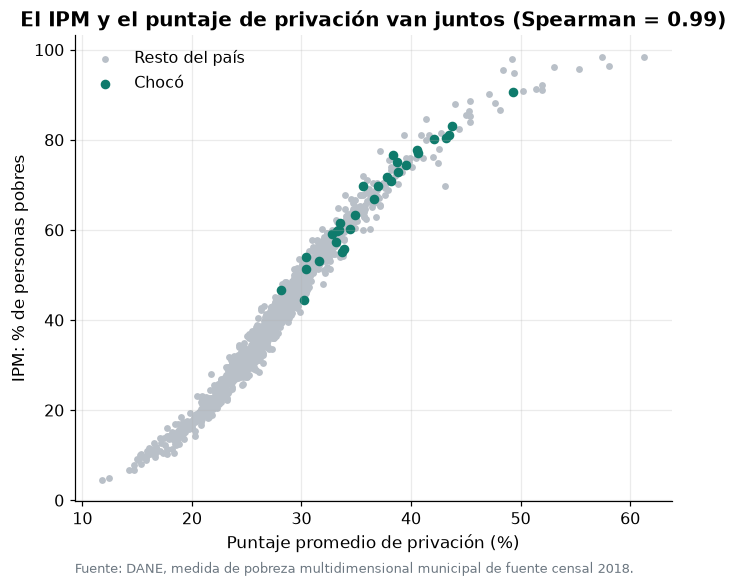

In [6]:
base["privacion_ponderada"] = ipm.privacion_ponderada_agregado(base)
r = base[["ipm", "privacion_ponderada"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(base.loc[~base.es_choco, "privacion_ponderada"], base.loc[~base.es_choco, "ipm"],
           s=12, color=RESTO, label="Resto del país")
ax.scatter(base.loc[base.es_choco, "privacion_ponderada"], base.loc[base.es_choco, "ipm"],
           s=28, color=CHOCO, label="Chocó")
ax.set(xlabel="Puntaje promedio de privación (%)", ylabel="IPM: % de personas pobres",
       title=f"El IPM y el puntaje de privación van juntos (Spearman = {r:.2f})")
ax.legend()
fuente(ax, "DANE, medida de pobreza multidimensional municipal de fuente censal 2018.")
guardar(fig, "01_coherencia_ipm")
plt.show()

## Lo que hay que tener en cuenta

- **El IPM municipal es de 2018.** Es la foto más detallada, pero no muestra lo que pasó después.
  Para ver la evolución se usa la serie **departamental** (Encuesta de Calidad de Vida, 2018 en adelante),
  que no llega a municipios.
- **El censo de 2018 tuvo omisión alta en algunas zonas del Chocó**, sobre todo rurales. El DANE ajustó la
  población por cobertura, pero las privaciones se calcularon con los hogares que sí se censaron.
- **Salud y empleo formal no salen del censo**, sino de registros administrativos (BDUA y PILA).
  Donde esos registros son débiles, el indicador puede subestimar o sobrestimar la privación.